# 03 - Entrenamiento, selección y calibración del modelo

Corresponde a las etapas de **Preparación de los datos** y **Modelado** del proceso CRISP-DM y al **objetivo específico 2**: comparar la capacidad discriminativa y la calibración de Random Forest, XGBoost y LightGBM con la regresión logística, empleando los mismos predictores, particiones y procedimiento de evaluación.

Aplica las secciones 3 a 6 de `docs/protocolo_analisis.md`:

1. Cuatro algoritmos con los mismos predictores y las mismas 5 particiones estratificadas (semilla 42), **solo con datos 2021–2024**.
2. Hiperparámetros elegidos por AUC-ROC media en validación cruzada.
3. Regla prefijada de elección del algoritmo: el de mayor AUC-ROC media; si su ventaja sobre la regresión logística es menor a 0.01, se elige la regresión logística.
4. Calibración con predicciones fuera de partición; recalibración sigmoide si la pendiente queda fuera de [0.9, 1.1].
5. Umbral: máxima especificidad con sensibilidad ≥ 0.70, calculado con predicciones fuera de partición.
6. Sin corrección del desbalance de clases.

Se entrenan dos versiones: **modelo completo** (todos los predictores) y **modelo web** (solo variables que el usuario puede reportar). Al final, todos los modelos se **congelan** en `models/v2/` para la evaluación única con los datos 2025 (notebook 04).

In [1]:
import json
import subprocess
import warnings
from datetime import date
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import statsmodels.api as sm
import xgboost
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from preparacion import DESENLACE, PREDICTORES_COMPLETO, PREDICTORES_WEB, cargar_desarrollo

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.float_format', '{:.4f}'.format)

SEMILLA = 42
SALIDA = Path('../resultados/03_entrenamiento')
MODELOS = Path('../models/v2')
SALIDA.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

d = cargar_desarrollo()
y = d[DESENLACE].astype(int)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
VERSIONES = {'completo': PREDICTORES_COMPLETO, 'web': PREDICTORES_WEB}

print(f'Desarrollo 2021-2024: {len(d)} registros, {y.sum()} con diagnóstico autorreportado ({100 * y.mean():.2f}%)')
print(f'scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | lightgbm {lightgbm.__version__}')

Desarrollo 2021-2024: 8909 registros, 562 con diagnóstico autorreportado (6.31%)
scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0


## Preprocesamiento y algoritmos

El preprocesamiento va dentro de cada `Pipeline`, de modo que en la validación cruzada se ajusta solo con los datos de entrenamiento de cada partición: imputación con la mediana (continuas) o la moda (binarias y ordinales) y, solo para la regresión logística, escalado estándar. Las mallas de hiperparámetros son las de la sección 5 del protocolo.

In [2]:
CONTINUAS = {'edad', 'imc', 'cintura', 'frutas_dias', 'verduras_dias', 'pas', 'pad'}


def preprocesador(predictores, escalar):
    continuas = [p for p in predictores if p in CONTINUAS]
    categoricas = [p for p in predictores if p not in CONTINUAS]
    pasos_cont = [('imputar', SimpleImputer(strategy='median'))] + ([('escalar', StandardScaler())] if escalar else [])
    pasos_cat = [('imputar', SimpleImputer(strategy='most_frequent'))] + ([('escalar', StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ('continuas', Pipeline(pasos_cont), continuas),
        ('categoricas', Pipeline(pasos_cat), categoricas),
    ])


ALGORITMOS = {
    'Regresión logística': (
        lambda: LogisticRegression(max_iter=5000),
        True,
        {'modelo__C': [0.01, 0.1, 1, 10]},
    ),
    'Random Forest': (
        lambda: RandomForestClassifier(n_estimators=500, random_state=SEMILLA, n_jobs=-1),
        False,
        {'modelo__max_depth': [4, 6, 8, None], 'modelo__min_samples_leaf': [10, 30, 50]},
    ),
    'XGBoost': (
        lambda: XGBClassifier(subsample=0.8, random_state=SEMILLA, n_jobs=-1, eval_metric='logloss'),
        False,
        {'modelo__n_estimators': [200, 500], 'modelo__max_depth': [2, 3, 4], 'modelo__learning_rate': [0.03, 0.1]},
    ),
    'LightGBM': (
        lambda: LGBMClassifier(min_child_samples=30, random_state=SEMILLA, n_jobs=-1, verbose=-1),
        False,
        {'modelo__n_estimators': [200, 500], 'modelo__num_leaves': [7, 15, 31], 'modelo__learning_rate': [0.03, 0.1]},
    ),
}

## Validación cruzada (2021–2024)

Para cada versión y algoritmo se busca la mejor combinación de hiperparámetros y se obtienen las predicciones fuera de partición (*out-of-fold*), con las que se calculan AUC-ROC, AUC-PR y Brier score sin que ningún registro sea evaluado por un modelo que lo vio al entrenar.

In [3]:
busquedas, oof = {}, {}
filas = []
for version, predictores in VERSIONES.items():
    X = d[predictores]
    for nombre, (crear, escalar, malla) in ALGORITMOS.items():
        pipe = Pipeline([('prep', preprocesador(predictores, escalar)), ('modelo', crear())])
        gs = GridSearchCV(pipe, malla, scoring='roc_auc', cv=folds, n_jobs=-1).fit(X, y)
        p = cross_val_predict(gs.best_estimator_, X, y, cv=folds, method='predict_proba')[:, 1]
        busquedas[(version, nombre)], oof[(version, nombre)] = gs, p
        i = gs.best_index_
        filas.append({
            'version': version, 'algoritmo': nombre,
            'AUC_ROC_media': gs.cv_results_['mean_test_score'][i],
            'AUC_ROC_de': gs.cv_results_['std_test_score'][i],
            'AUC_PR_oof': average_precision_score(y, p),
            'Brier_oof': brier_score_loss(y, p),
            'hiperparametros': {k.replace('modelo__', ''): v for k, v in gs.best_params_.items()},
        })

cv = pd.DataFrame(filas)
cv['Brier_nulo'] = brier_score_loss(y, np.full(len(y), y.mean()))
cv.to_csv(SALIDA / 'validacion_cruzada.csv', index=False)
cv

,version,algoritmo,AUC_ROC_media,AUC_ROC_de,AUC_PR_oof,Brier_oof,hiperparametros,Brier_nulo
0,completo,Regresión logística,0.7828,0.0293,0.2223,0.0538,{'C': 0.1},0.0591
1,completo,Random Forest,0.7815,0.0271,0.2158,0.0541,"{'max_depth': None, 'min_samples_leaf': 50}",0.0591
2,completo,XGBoost,0.7823,0.0292,0.2167,0.0538,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.0591
3,completo,LightGBM,0.7763,0.0317,0.2130,0.0541,"{'learning_rate': 0.03, 'n_estimators': 200, '...",0.0591
4,web,Regresión logística,0.7815,0.0314,0.2241,0.0538,{'C': 1},0.0591
5,web,Random Forest,0.7798,0.0309,0.2163,0.0538,"{'max_depth': 8, 'min_samples_leaf': 30}",0.0591
6,web,XGBoost,0.7795,0.0330,0.2129,0.0539,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.0591
7,web,LightGBM,0.7768,0.0369,0.2060,0.0542,"{'learning_rate': 0.03, 'n_estimators': 200, '...",0.0591


## Elección del algoritmo (regla prefijada)

Para cada versión se identifica el algoritmo con mayor AUC-ROC media. Si su ventaja sobre la regresión logística es menor a 0.01, se elige la regresión logística por parsimonia e interpretabilidad.

In [4]:
seleccion = {}
for version in VERSIONES:
    t = cv[cv['version'] == version].set_index('algoritmo')['AUC_ROC_media']
    mejor = t.idxmax()
    ventaja = t[mejor] - t['Regresión logística']
    elegido = 'Regresión logística' if ventaja < 0.01 else mejor
    seleccion[version] = elegido
    print(f'{version:9s}: mayor AUC = {mejor} ({t[mejor]:.4f}); ventaja sobre la regresión logística = {ventaja:+.4f} '
          f'-> se elige: {elegido}')

completo : mayor AUC = Regresión logística (0.7828); ventaja sobre la regresión logística = +0.0000 -> se elige: Regresión logística
web      : mayor AUC = Regresión logística (0.7815); ventaja sobre la regresión logística = +0.0000 -> se elige: Regresión logística


## Calibración (predicciones fuera de partición)

Pendiente e intercepto de calibración: la pendiente proviene de una regresión logística del desenlace sobre el logit de la probabilidad predicha; el intercepto (calibración global) se estima con el logit como *offset*. Si la pendiente queda fuera de [0.9, 1.1], el modelo se recalibra con `CalibratedClassifierCV` (sigmoide, 5 particiones) y se recalculan sus predicciones fuera de partición.

In [5]:
def calibracion(y_real, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))
    pendiente = sm.Logit(y_real, sm.add_constant(lp)).fit(disp=False).params.iloc[1]
    intercepto = sm.GLM(y_real, np.ones(len(lp)), offset=lp, family=sm.families.Binomial()).fit().params.iloc[0]
    return pendiente, intercepto


finales, filas = {}, []
for (version, nombre), gs in busquedas.items():
    X = d[VERSIONES[version]]
    pendiente, intercepto = calibracion(y, oof[(version, nombre)])
    recalibrar = not 0.9 <= pendiente <= 1.1
    modelo = gs.best_estimator_
    if recalibrar:
        modelo = CalibratedClassifierCV(gs.best_estimator_, method='sigmoid', cv=folds)
        oof[(version, nombre)] = cross_val_predict(modelo, X, y, cv=folds, method='predict_proba')[:, 1]
    pend_final, inter_final = calibracion(y, oof[(version, nombre)])
    finales[(version, nombre)] = modelo
    filas.append({
        'version': version, 'algoritmo': nombre,
        'pendiente_inicial': pendiente, 'intercepto_inicial': intercepto, 'recalibrado': recalibrar,
        'pendiente_final': pend_final, 'intercepto_final': inter_final,
        'AUC_ROC_oof_final': roc_auc_score(y, oof[(version, nombre)]),
        'Brier_oof_final': brier_score_loss(y, oof[(version, nombre)]),
    })

calib = pd.DataFrame(filas)
calib.to_csv(SALIDA / 'calibracion.csv', index=False)
calib

,version,algoritmo,pendiente_inicial,intercepto_inicial,recalibrado,pendiente_final,intercepto_final,AUC_ROC_oof_final,Brier_oof_final
0,completo,Regresión logística,0.9943,0.0011,False,0.9943,0.0011,0.7822,0.0538
1,completo,Random Forest,1.1693,0.0008,True,1.0199,-0.0003,0.7793,0.0540
2,completo,XGBoost,1.0081,-0.0026,False,1.0081,-0.0026,0.7787,0.0538
3,completo,LightGBM,0.9572,0.0052,False,0.9572,0.0052,0.7743,0.0541
4,web,Regresión logística,0.9823,0.0004,False,0.9823,0.0004,0.7806,0.0538
5,web,Random Forest,1.0369,0.0010,False,1.0369,0.0010,0.7780,0.0538
6,web,XGBoost,0.9971,-0.0011,False,0.9971,-0.0011,0.7778,0.0539
7,web,LightGBM,0.9525,0.0017,False,0.9525,0.0017,0.7747,0.0542


## Umbral de clasificación

Con las predicciones fuera de partición finales, el umbral que maximiza la especificidad manteniendo una sensibilidad ≥ 0.70. El umbral solo se usa para reportar sensibilidad y especificidad; el sistema web no muestra categorías de riesgo.

In [6]:
def umbral_sensibilidad(y_real, p, sensibilidad_min=0.70):
    fpr, tpr, umbrales = roc_curve(y_real, p)
    ok = tpr >= sensibilidad_min
    i = np.argmax(np.where(ok, 1 - fpr, -1))
    return umbrales[i], tpr[i], 1 - fpr[i]


umbrales, filas = {}, []
for clave, p in oof.items():
    u, sens, esp = umbral_sensibilidad(y, p)
    umbrales[clave] = float(u)
    filas.append({'version': clave[0], 'algoritmo': clave[1], 'umbral': u, 'sensibilidad_oof': sens, 'especificidad_oof': esp})
tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales.to_csv(SALIDA / 'umbrales.csv', index=False)
tabla_umbrales

,version,algoritmo,umbral,sensibilidad_oof,especificidad_oof
0,completo,Regresión logística,0.0589,0.7011,0.7307
1,completo,Random Forest,0.0556,0.7011,0.7191
2,completo,XGBoost,0.0697,0.7011,0.7258
3,completo,LightGBM,0.0622,0.7011,0.7092
4,web,Regresión logística,0.0599,0.7011,0.7351
5,web,Random Forest,0.0753,0.7011,0.7321
6,web,XGBoost,0.0731,0.7011,0.7351
7,web,LightGBM,0.0705,0.7011,0.7360


## Congelamiento de los modelos

Cada modelo final se reentrena con todos los datos 2021–2024 y se guarda en `models/v2/` junto con sus predictores, umbral, métricas de validación cruzada, versiones de las librerías y el commit de Git. A partir de aquí **ningún modelo, hiperparámetro ni umbral se modifica**: el notebook 04 los evalúa una sola vez con los datos 2025.

In [7]:
try:
    commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
except OSError:
    commit = None

SLUG = {'Regresión logística': 'regresion_logistica', 'Random Forest': 'random_forest', 'XGBoost': 'xgboost', 'LightGBM': 'lightgbm'}
registro = []
for (version, nombre), modelo in finales.items():
    predictores = VERSIONES[version]
    ajustado = modelo.fit(d[predictores], y)
    fila_cv = cv[(cv['version'] == version) & (cv['algoritmo'] == nombre)].iloc[0]
    fila_cal = calib[(calib['version'] == version) & (calib['algoritmo'] == nombre)].iloc[0]
    artefacto = {
        'modelo': ajustado,
        'version': version,
        'algoritmo': nombre,
        'predictores': predictores,
        'umbral': umbrales[(version, nombre)],
        'seleccionado': seleccion[version] == nombre,
        'recalibrado': bool(fila_cal['recalibrado']),
        'hiperparametros': fila_cv['hiperparametros'],
        'auc_cv': float(fila_cv['AUC_ROC_media']),
        'desenlace': 'Diagnóstico autorreportado de DM (ENDES QS109)',
        'datos_entrenamiento': 'ENDES 2021-2024, Lima Metropolitana, 30-69 años',
        'versiones': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'lightgbm': lightgbm.__version__},
        'fecha': date.today().isoformat(),
        'commit_git': commit,
    }
    ruta = MODELOS / f'{version}_{SLUG[nombre]}.joblib'
    joblib.dump(artefacto, ruta, compress=3)
    registro.append({'archivo': ruta.name, 'seleccionado': artefacto['seleccionado'], 'MB': ruta.stat().st_size / 1e6})

(MODELOS / 'seleccion.json').write_text(json.dumps(
    {v: f'{v}_{SLUG[a]}.joblib' for v, a in seleccion.items()}, ensure_ascii=False, indent=2), encoding='utf-8')
pd.DataFrame(registro)

,archivo,seleccionado,MB
0,completo_regresion_logistica.joblib,True,0.0024
1,completo_random_forest.joblib,False,10.3867
2,completo_xgboost.joblib,False,0.0296
3,completo_lightgbm.joblib,False,0.0627
4,web_regresion_logistica.joblib,True,0.0022
5,web_random_forest.joblib,False,1.8153
6,web_xgboost.joblib,False,0.0296
7,web_lightgbm.joblib,False,0.0617


## Interpretación del modelo web seleccionado (SHAP)

Valores SHAP calculados sobre los datos 2021–2024 para el modelo que usará el sistema web. Muestran qué variables influyen más en la probabilidad estimada y en qué dirección. Se emplea una muestra de 1,000 registros para la explicación y 200 como fondo.

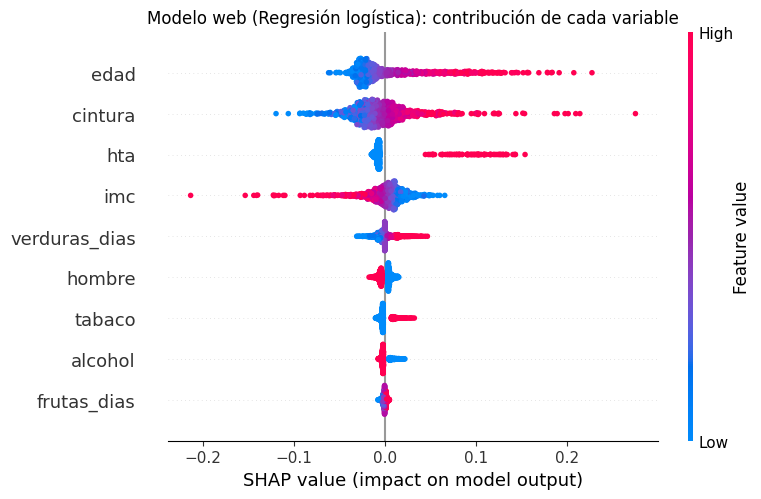

,variable,media_abs_SHAP
0,edad,0.0325
3,cintura,0.0255
4,hta,0.0166
2,imc,0.0157
8,verduras_dias,0.0079
1,hombre,0.0058
5,tabaco,0.0051
6,alcohol,0.0043
7,frutas_dias,0.0017


In [8]:
web = finales[('web', seleccion['web'])]
Xw = d[PREDICTORES_WEB]
fondo = Xw.sample(200, random_state=SEMILLA)
muestra = Xw.sample(1000, random_state=SEMILLA + 1)

explicador = shap.Explainer(lambda X: web.predict_proba(pd.DataFrame(X, columns=PREDICTORES_WEB))[:, 1],
                            fondo, feature_names=PREDICTORES_WEB)
valores = explicador(muestra)

importancia = pd.DataFrame({
    'variable': PREDICTORES_WEB,
    'media_abs_SHAP': np.abs(valores.values).mean(axis=0),
}).sort_values('media_abs_SHAP', ascending=False)
importancia.to_csv(SALIDA / 'shap_importancia_web.csv', index=False)

shap.plots.beeswarm(valores, show=False, max_display=len(PREDICTORES_WEB))
plt.title(f"Modelo web ({seleccion['web']}): contribución de cada variable")
plt.tight_layout()
plt.savefig(SALIDA / 'shap_resumen_web.png', dpi=150)
plt.show()
importancia

## Interpretación

**Comparación de algoritmos (OE2).** En ambas versiones, los cuatro algoritmos obtuvieron un desempeño muy similar en la validación cruzada (AUC-ROC entre 0.776 y 0.783), y la regresión logística obtuvo la mayor AUC-ROC media. Por la regla prefijada, se selecciona la **regresión logística** tanto para el modelo completo como para el modelo web. Este resultado es coherente con Christodoulou et al. (2019), que no encontraron ventaja de los algoritmos de Machine Learning sobre la regresión logística en modelos de predicción clínica, y con Olivera et al. (2017), que eligieron la regresión logística para su herramienta web. La significancia de las diferencias se contrasta en el notebook 04 con la prueba de DeLong sobre los datos 2025.

**Modelo web frente al modelo completo.** Con solo las variables que el usuario puede reportar, el modelo web alcanza prácticamente el mismo desempeño que el modelo completo (AUC-ROC 0.782 frente a 0.783), por lo que omitir la presión medida, el nivel educativo, el seguro de salud y el índice de riqueza no implica una pérdida relevante.

**Calibración.** Todos los modelos presentan pendientes cercanas a 1 e interceptos cercanos a 0. Solo el Random Forest completo (pendiente 1.17) requirió recalibración. Todos superan al modelo nulo en Brier score (0.054 frente a 0.059).

**Umbral.** Con sensibilidad de 0.70, la especificidad fuera de partición del modelo web es de 0.74. El umbral (≈ 0.06) es bajo porque la prevalencia del diagnóstico autorreportado es de 6.3%.

**Interpretación SHAP del modelo web.** La edad, el perímetro abdominal, la hipertensión diagnosticada y el IMC son las variables con mayor contribución, en concordancia con los factores asociados identificados en el notebook 02. Al igual que en ese análisis, el coeficiente del IMC es negativo porque el modelo también incluye el perímetro abdominal (r ≈ 0.90): su efecto se interpreta *a igual perímetro abdominal*. Por ello, en la presentación de resultados del sistema web conviene mostrar IMC y perímetro abdominal como un único factor de composición corporal, sin modificar el modelo.

Todas estas métricas son de validación cruzada sobre 2021–2024 y se interpretan como concordancia con el diagnóstico autorreportado. Los modelos quedan congelados en `models/v2/`.